In [1]:
import pandas as pd
from functools import reduce
import numpy as np  

In [2]:
#Wczytanie danych
SGN=pd.read_csv("Dane/SGN_d.csv")
SGN["Data"] = pd.to_datetime(SGN["Data"])
SGN = SGN.sort_values("Data")
SGN = SGN[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_SGN"})

SGN = SGN.sort_values("Data").reset_index(drop=True)
SGN = SGN[(SGN["Data"] >= "2015-01-01") & (SGN["Data"] <= "2019-12-31")]
SGN = SGN.reset_index(drop=True)

SGN

,Data,Close_SGN
0,2015-01-02,13.65
1,2015-01-05,13.46
2,2015-01-07,13.24
3,2015-01-08,13.70
4,2015-01-09,13.83
...,...,...
1227,2019-12-19,2.52
1228,2019-12-20,2.58
1229,2019-12-23,2.50
1230,2019-12-27,2.55


In [3]:
SGN['Log_Return'] = np.log(SGN['Close_SGN'] / SGN['Close_SGN'].shift(1))

SGN

,Data,Close_SGN,Log_Return
0,2015-01-02,13.65,NaN
1,2015-01-05,13.46,-0.014017
2,2015-01-07,13.24,-0.016480
3,2015-01-08,13.70,0.034153
4,2015-01-09,13.83,0.009444
...,...,...,...
1227,2019-12-19,2.52,0.069844
1228,2019-12-20,2.58,0.023530
1229,2019-12-23,2.50,-0.031499
1230,2019-12-27,2.55,0.019803


In [4]:
SGN['Close_SGN'].describe()

count    1232.000000
mean        5.609838
std         3.289460
min         1.995000
25%         2.980000
50%         4.320000
75%         7.770000
max        14.420000
Name: Close_SGN, dtype: float64

In [5]:
SGN['Log_Return'].describe()

count    1231.000000
mean       -0.001366
std         0.033744
min        -0.187862
25%        -0.016529
50%        -0.001206
75%         0.013116
max         0.261014
Name: Log_Return, dtype: float64

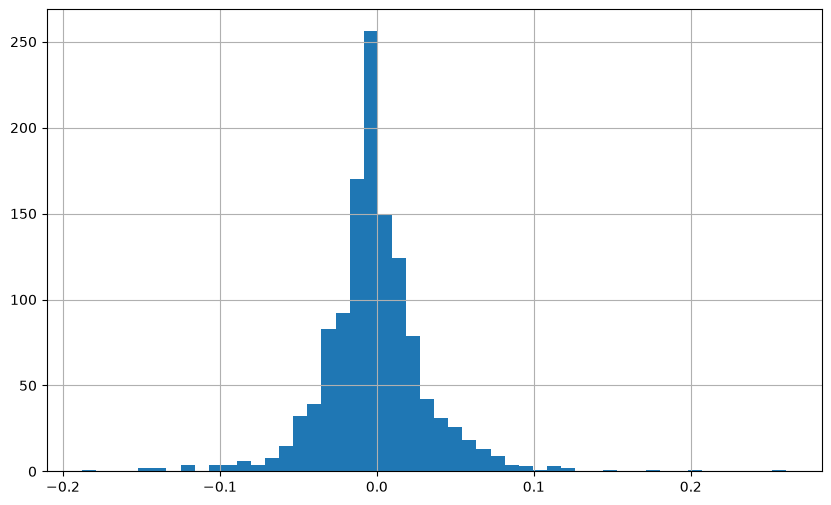

In [6]:
hist_SGN = SGN['Log_Return'].hist(bins=50, figsize=(10, 6))